# Answer key: investigations for Parts 8 and 9

**Spoilers.** This notebook contains worked answers to the simulation study (Part 8) and the misspecification experiments (Part 9). Do your own first.

The likelihood surface and EM path asked for in Part 8 are in `gp_em_tutorial.ipynb`, section 8.

Everything here uses the same setup as the worksheet: 100 evenly spaced points on $[0, 10]$, true $s^2 = 2$, $\sigma^2 = 0.25$, lengthscale 1.

In [1]:
import os
# Many small matrix operations run slower, not faster, when the linear algebra
# library spreads each one over several threads. Must be set before NumPy loads.
os.environ["OMP_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "1"

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

import gp_em

C_F, C_Y, C_POST, C_REF = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 2, "legend.frameon": False,
})

N, ELL, TRUE_S2, TRUE_SIGMA2 = 100, 1.0, 2.0, 0.25
x = np.linspace(0, 10, N)
R = 200  # number of simulated datasets per experiment

## Tools

Three small helpers.

- `fit` runs EM and returns the final parameters.
- `posterior` returns the estimate $m$ and its pointwise standard deviation.
- `loo_residuals` is the diagnostic for Part 9. For each point $i$ it predicts $y_i$ from *all the other points* and reports (actual − predicted) / (predicted sd). If the model is right these are approximately standard normal, and **computing them needs no knowledge of the true $f$**. There is a shortcut that avoids refitting 100 times: with $\alpha = C^{-1}y$, the standardised leave-one-out residual is $\alpha_i / \sqrt{[C^{-1}]_{ii}}$.

In [2]:
def fit(K, y):
    h = gp_em.run_em(K, y, n_iter=500, tol=1e-6)
    return h["s2"][-1], h["sigma2"][-1]

def posterior(K, y, s2, sigma2):
    m, S, _, _ = gp_em.e_step(K, y, s2, sigma2)
    return m, np.sqrt(np.maximum(np.diag(S), 0))

def loo_residuals(K, y, s2, sigma2):
    c = cho_factor(s2 * K + sigma2 * np.eye(len(y)), lower=True)
    C_inv = cho_solve(c, np.eye(len(y)))
    return (C_inv @ y) / np.sqrt(np.diag(C_inv))

def lag1_autocorrelation(z):
    z = z - z.mean()
    return (z[:-1] @ z[1:]) / (z @ z)

def baseline(seed):
    _, f, y = gp_em.sample_data(N, TRUE_S2, TRUE_SIGMA2, ELL, seed=seed)
    return f, y

def study(make_data, fit_lengthscale=ELL, regions=None):
    # Fit R datasets. Per dataset: s2, sigma2, RMSE of m against f, coverage of
    # m +/- 2 sd, three LOO summaries, coverage within each region mask, then var(z).
    K = gp_em.rbf_kernel(x, x, fit_lengthscale)
    rows = []
    for seed in range(R):
        f, y = make_data(seed)
        s2, sigma2 = fit(K, y)
        m, sd = posterior(K, y, s2, sigma2)
        covered = np.abs(m - f) <= 2 * sd
        z = loo_residuals(K, y, s2, sigma2)
        row = [s2, sigma2, np.sqrt(np.mean((m - f) ** 2)), covered.mean(),
               lag1_autocorrelation(z), np.mean(np.abs(z) > 3), np.var(z[x < 5]) / np.var(z[x >= 5])]
        row += [covered[mask].mean() for mask in (regions or [])]
        row.append(np.var(z))  # always the last column
        rows.append(row)
    return np.array(rows)

## Part 8: how good are the estimates when the model is right?

One dataset tells you nothing about how reliable a method is. So: simulate many datasets from the true model, fit each, and look at the spread.

s2    : truth 2.00   mean 1.931   median 1.737   middle 90% of estimates [0.71, 3.73]
sigma2: truth 0.25   mean 0.251   median 0.249   middle 90% of estimates [0.19, 0.31]


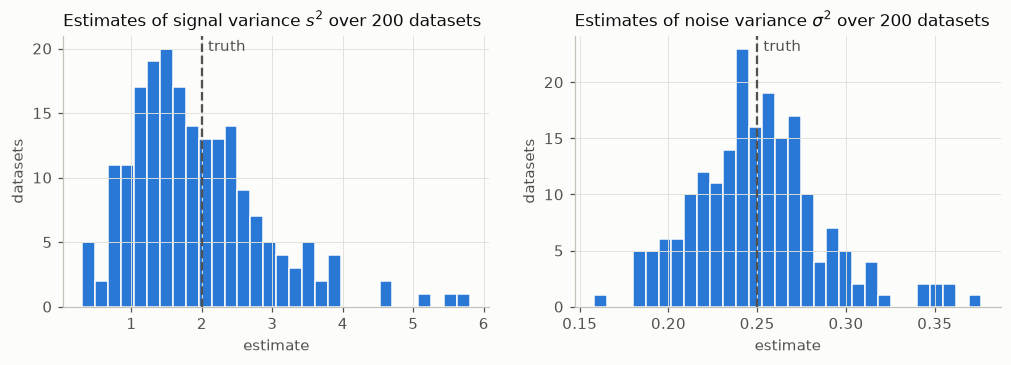

In [3]:
base = study(baseline)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col, truth, name in [(axes[0], 0, TRUE_S2, "signal variance $s^2$"), (axes[1], 1, TRUE_SIGMA2, "noise variance $\\sigma^2$")]:
    ax.hist(base[:, col], bins=30, color=C_F, edgecolor="#fcfcfb", linewidth=1)
    ax.axvline(truth, color=C_REF, ls="--", lw=1.5)
    ax.annotate("truth", (truth, ax.get_ylim()[1]), xytext=(4, -10), textcoords="offset points", color=C_REF)
    ax.set(title=f"Estimates of {name} over {R} datasets", xlabel="estimate", ylabel="datasets")

for col, truth, name in [(0, TRUE_S2, "s2    "), (1, TRUE_SIGMA2, "sigma2")]:
    lo, mid, hi = np.percentile(base[:, col], [5, 50, 95])
    print(f"{name}: truth {truth:.2f}   mean {base[:, col].mean():.3f}   median {mid:.3f}   middle 90% of estimates [{lo:.2f}, {hi:.2f}]")

Both estimators are centred near the truth, but their precision is completely different. $\sigma^2$ is pinned down to within roughly a quarter of its value either way. $s^2$ ranges over more than a factor of five. Same data, same method.

Next: do the uncertainty bands mean what they say? A band of $m \pm 2\,\text{sd}$ should contain the true $f$ at about 95% of points.

In [4]:
K_true = gp_em.rbf_kernel(x, x, ELL)
cover_true = []
for seed in range(R):
    f, y = baseline(seed)
    m, sd = posterior(K_true, y, TRUE_S2, TRUE_SIGMA2)
    cover_true.append(np.mean(np.abs(m - f) <= 2 * sd))

print(f"coverage of m ± 2 sd using the true parameters:      {np.mean(cover_true):.3f}")
print(f"coverage of m ± 2 sd using the estimated parameters: {base[:, 3].mean():.3f}")
print(f"nominal coverage of ± 2 sd for a Gaussian:           0.954")
print(f"share of datasets with coverage below 85% (estimated parameters): {np.mean(base[:, 3] < 0.85):.3f}")

coverage of m ± 2 sd using the true parameters:      0.951
coverage of m ± 2 sd using the estimated parameters: 0.946
nominal coverage of ± 2 sd for a Gaussian:           0.954
share of datasets with coverage below 85% (estimated parameters): 0.050


On average the bands are honest, even though they are built from an $s^2$ estimate that is often far from the truth. The bands also ignore the uncertainty in the parameters themselves (they treat the estimates as exact), and that costs very little here.

### What kind of extra data helps $s^2$?

Two ways to quadruple the data: pack 400 points into the same interval, or keep the spacing and make the interval four times longer. (This uses the direct optimiser because it is faster at $n = 400$.)

In [5]:
def s2_spread(n, x_max, reps=100):
    xs = np.linspace(0, x_max, n)
    Kn = gp_em.rbf_kernel(xs, xs, ELL)
    est = []
    for seed in range(reps):
        _, _, yn = gp_em.sample_data(n, TRUE_S2, TRUE_SIGMA2, ELL, seed=seed, x_max=x_max)
        est.append(gp_em.fit_direct(Kn, yn)[:2])
    return np.array(est)

for label, n, x_max in [("100 points on [0, 10]", 100, 10.0), ("400 points on [0, 10]", 400, 10.0), ("400 points on [0, 40]", 400, 40.0)]:
    est = s2_spread(n, x_max)
    a, b = np.percentile(est[:, 0], [5, 95]); c, d = np.percentile(est[:, 1], [5, 95])
    print(f"{label}:  middle 90% of s2 estimates [{a:.2f}, {b:.2f}]   of sigma2 estimates [{c:.3f}, {d:.3f}]")

100 points on [0, 10]:  middle 90% of s2 estimates [0.67, 3.57]   of sigma2 estimates [0.189, 0.304]


400 points on [0, 10]:  middle 90% of s2 estimates [0.85, 3.31]   of sigma2 estimates [0.222, 0.285]


400 points on [0, 40]:  middle 90% of s2 estimates [1.27, 2.84]   of sigma2 estimates [0.220, 0.285]


Packing in more points sharpens $\sigma^2$ but narrows the $s^2$ range only slightly. Extending the interval narrows it much more. The information about $s^2$ is the number of independent wiggles observed, which depends on (interval length) / (lengthscale), not on $n$.

## Part 9: when the model is wrong

Each experiment changes exactly one thing about how the data are generated (or about the lengthscale used to fit) and keeps the fitting code unchanged.

| Experiment | What is changed |
|---|---|
| Lengthscale too short | fit with $\ell = 0.3$ (truth 1) |
| Lengthscale too long | fit with $\ell = 3$ (truth 1) |
| Outliers | 5 of the 100 points get noise with sd 3 instead of 0.5 |
| Noise varies with $x$ | noise sd rises linearly from 0.1 at $x=0$ to 1.1 at $x=10$ |
| Jump | the true function has 3 added to it for $x > 5$ |

In [6]:
def outliers(seed):
    f, y = baseline(seed)
    rng = np.random.default_rng(10_000 + seed)
    idx = rng.choice(N, 5, replace=False)
    y = y.copy()
    y[idx] = f[idx] + 3.0 * rng.standard_normal(5)
    return f, y

def varying_noise(seed):
    f, _ = baseline(seed)
    rng = np.random.default_rng(20_000 + seed)
    return f, f + (0.1 + 0.1 * x) * rng.standard_normal(N)

def jump(seed):
    f, _ = baseline(seed)
    rng = np.random.default_rng(30_000 + seed)
    f = f + 3.0 * (x > 5)
    return f, f + np.sqrt(TRUE_SIGMA2) * rng.standard_normal(N)

near_jump = np.abs(x - 5) < 0.5
results = {
    "model correct": base,
    "lengthscale too short (0.3)": study(baseline, fit_lengthscale=0.3),
    "lengthscale too long (3)": study(baseline, fit_lengthscale=3.0),
    "outliers": study(outliers),
    "noise varies with x": study(varying_noise, regions=[x < 5, x >= 5]),
    "jump at x = 5": study(jump, regions=[near_jump, ~near_jump]),
}

print("What went wrong (needs the true f, so only available in simulation)\n")
print(f"{'experiment':30s} {'median s2':>10s} {'median sigma2':>14s} {'RMSE of m':>10s} {'coverage':>9s}")
for name, r in results.items():
    print(f"{name:30s} {np.median(r[:, 0]):10.2f} {np.median(r[:, 1]):14.3f} {r[:, 2].mean():10.3f} {r[:, 3].mean():9.3f}")

r = results["noise varies with x"]
print(f"\nnoise varies with x: coverage for x < 5: {r[:, 7].mean():.3f}   for x >= 5: {r[:, 8].mean():.3f}")
r = results["jump at x = 5"]
print(f"jump at x = 5:       coverage within 0.5 of the jump: {r[:, 7].mean():.3f}   elsewhere: {r[:, 8].mean():.3f}")

What went wrong (needs the true f, so only available in simulation)

experiment                      median s2  median sigma2  RMSE of m  coverage
model correct                        1.74          0.249      0.167     0.946
lengthscale too short (0.3)          0.98          0.236      0.244     0.959
lengthscale too long (3)            73.40          0.333      0.347     0.604
outliers                             1.77          0.639      0.259     0.941
noise varies with x                  1.78          0.441      0.214     0.934
jump at x = 5                        5.01          0.329      0.324     0.893

noise varies with x: coverage for x < 5: 0.993   for x >= 5: 0.875
jump at x = 5:       coverage within 0.5 of the jump: 0.246   elsewhere: 0.965


Reading the table against the first row:

- **Lengthscale too short** costs accuracy (higher RMSE) but the bands stay honest. The model is too flexible, knows it, and reports wide bands.
- **Lengthscale too long** is the dangerous one. The model cannot bend fast enough to follow $f$, pushes the misfit into $\sigma^2$, and reports bands that are far too narrow. The $s^2$ estimate becomes meaningless.
- **Outliers** inflate $\sigma^2$ (one number has to cover both ordinary and wild points), which over-smooths everywhere. Coverage of $f$ barely moves.
- **Noise that varies with $x$**: the overall coverage looks nearly fine, which hides that it is too high where the noise is small and too low where it is large. An average can conceal a problem that matters locally.
- **Jump**: fine away from the jump, badly wrong next to it. A smooth kernel cannot represent a discontinuity, and $s^2$ is inflated trying.

### A warning light that does not need the truth

Summaries of the leave-one-out residuals, which use only $y$:

In [7]:
print(f"{'experiment':30s} {'variance':>9s} {'lag-1 autocorr':>15s} {'share |z| > 3':>14s} {'var(z, x<5) / var(z, x>=5)':>28s}")
for name, r in results.items():
    print(f"{name:30s} {r[:, -1].mean():9.2f} {r[:, 4].mean():15.2f} {r[:, 5].mean():14.4f} {np.median(r[:, 6]):28.2f}")
print(f"\nexpected for exact standard normal draws: share |z| > 3 = 0.0027, variance ratio = 1")

experiment                      variance  lag-1 autocorr  share |z| > 3   var(z, x<5) / var(z, x>=5)
model correct                       1.00           -0.11         0.0020                         0.95
lengthscale too short (0.3)         1.00           -0.37         0.0027                         0.94
lengthscale too long (3)            1.00            0.21         0.0018                         0.98
outliers                            1.00           -0.10         0.0204                         1.02
noise varies with x                 1.00           -0.12         0.0116                         0.20
jump at x = 5                       1.00            0.04         0.0074                         1.03

expected for exact standard normal draws: share |z| > 3 = 0.0027, variance ratio = 1


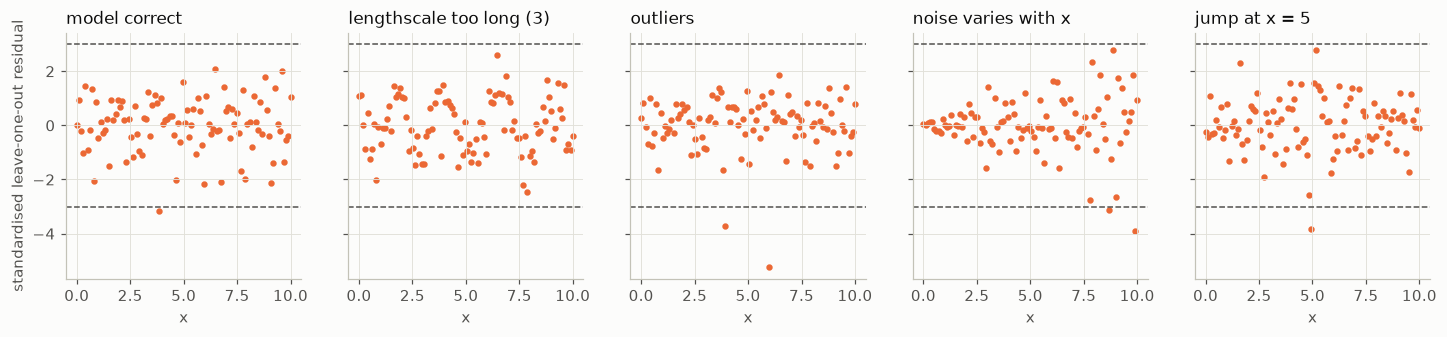

In [8]:
seed = 0
cases = [("model correct", baseline, ELL), ("lengthscale too long (3)", baseline, 3.0), ("outliers", outliers, ELL),
         ("noise varies with x", varying_noise, ELL), ("jump at x = 5", jump, ELL)]
fig, axes = plt.subplots(1, 5, figsize=(16, 2.9), sharey=True)
for ax, (name, make, ell) in zip(axes, cases):
    f, y = make(seed)
    Kc = gp_em.rbf_kernel(x, x, ell)
    z = loo_residuals(Kc, y, *fit(Kc, y))
    ax.axhline(3, color=C_REF, lw=1, ls="--"); ax.axhline(-3, color=C_REF, lw=1, ls="--")
    ax.scatter(x, z, s=10, color=C_Y)
    ax.set(title=name, xlabel="x")
axes[0].set_ylabel("standardised leave-one-out residual");

Each failure leaves a different fingerprint:

- **Wrong lengthscale** shows up in the autocorrelation of neighbouring residuals: positive when the lengthscale is too long (runs of same-sign misses), more negative than the baseline when it is too short.
- **Outliers** show up as far too many residuals beyond ±3.
- **Noise that varies with $x$** shows up as a fan shape: the spread of residuals differs between the two halves.
- **The jump** shows up as a few large residuals clustered at one location.

Note that the baseline autocorrelation is not zero. Leave-one-out residuals are not independent of one another even when the model is right, so the reference value for a diagnostic should come from simulating under the fitted model, not from textbook independence.

One thing these residuals cannot detect: their overall variance is close to 1 in every experiment, because the fitted variances are chosen to make it so. A diagnostic that the fit itself forces to look good carries no information.